**Detailed Problem Statement & Requirements**
Implement a supervised classification model on the Wine dataset. Handle feature scaling (StandardScaler), train/test dataset splitting (80/20), train Logistic Regression and Decision Tree models, and benchmark classification accuracy, precision, recall, and F1-score.

**1. Load the benchmark dataset using Pandas.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,f1_score,precision_score,recall_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay


In [2]:
data = pd.read_csv("wine_dataset.csv")
data.head(10)

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
5,1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450
6,1,14.39,1.87,2.45,14.6,96,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290
7,1,14.06,2.15,2.61,17.6,121,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295
8,1,14.83,1.64,2.17,14.0,97,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045
9,1,13.86,1.35,2.27,16.0,98,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045


In [3]:
data.tail(10)

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
168,3,13.58,2.58,2.69,24.5,105,1.55,0.84,0.39,1.54,8.660000,0.74,1.80,750
169,3,13.40,4.60,2.86,25.0,112,1.98,0.96,0.27,1.11,8.500000,0.67,1.92,630
170,3,12.20,3.03,2.32,19.0,96,1.25,0.49,0.40,0.73,5.500000,0.66,1.83,510
171,3,12.77,2.39,2.28,19.5,86,1.39,0.51,0.48,0.64,9.899999,0.57,1.63,470
172,3,14.16,2.51,2.48,20.0,91,1.68,0.70,0.44,1.24,9.700000,0.62,1.71,660
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.700000,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.300000,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.200000,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.300000,0.60,1.62,840
177,3,14.13,4.10,2.74,24.5,96,2.05,0.76,0.56,1.35,9.200000,0.61,1.60,560


In [4]:
# for visualize the column name, data types, Non-Null Count and total rows and columns
data.info()
data.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   class                         178 non-null    int64  
 1   Alcohol                       178 non-null    float64
 2   Malic acid                    178 non-null    float64
 3   Ash                           178 non-null    float64
 4   Alcalinity of ash             178 non-null    float64
 5   Magnesium                     178 non-null    int64  
 6   Total phenols                 178 non-null    float64
 7   Flavanoids                    178 non-null    float64
 8   Nonflavanoid phenols          178 non-null    float64
 9   Proanthocyanins               178 non-null    float64
 10  Color intensity               178 non-null    float64
 11  Hue                           178 non-null    float64
 12  OD280/OD315 of diluted wines  178 non-null    float64
 13  Proli

(178, 14)

In [5]:
# to show the statistical review of the dataset
data.describe()

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


**Data Cleaning**

In [6]:
# check the null values in columns
data.isnull().sum()

,0
class,0
Alcohol,0
Malic acid,0
Ash,0
Alcalinity of ash,0
Magnesium,0
Total phenols,0
Flavanoids,0
Nonflavanoid phenols,0
Proanthocyanins,0


In [7]:
data.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
173,False
174,False
175,False
176,False


**2. Perform exploratory pairplots with Seaborn.**

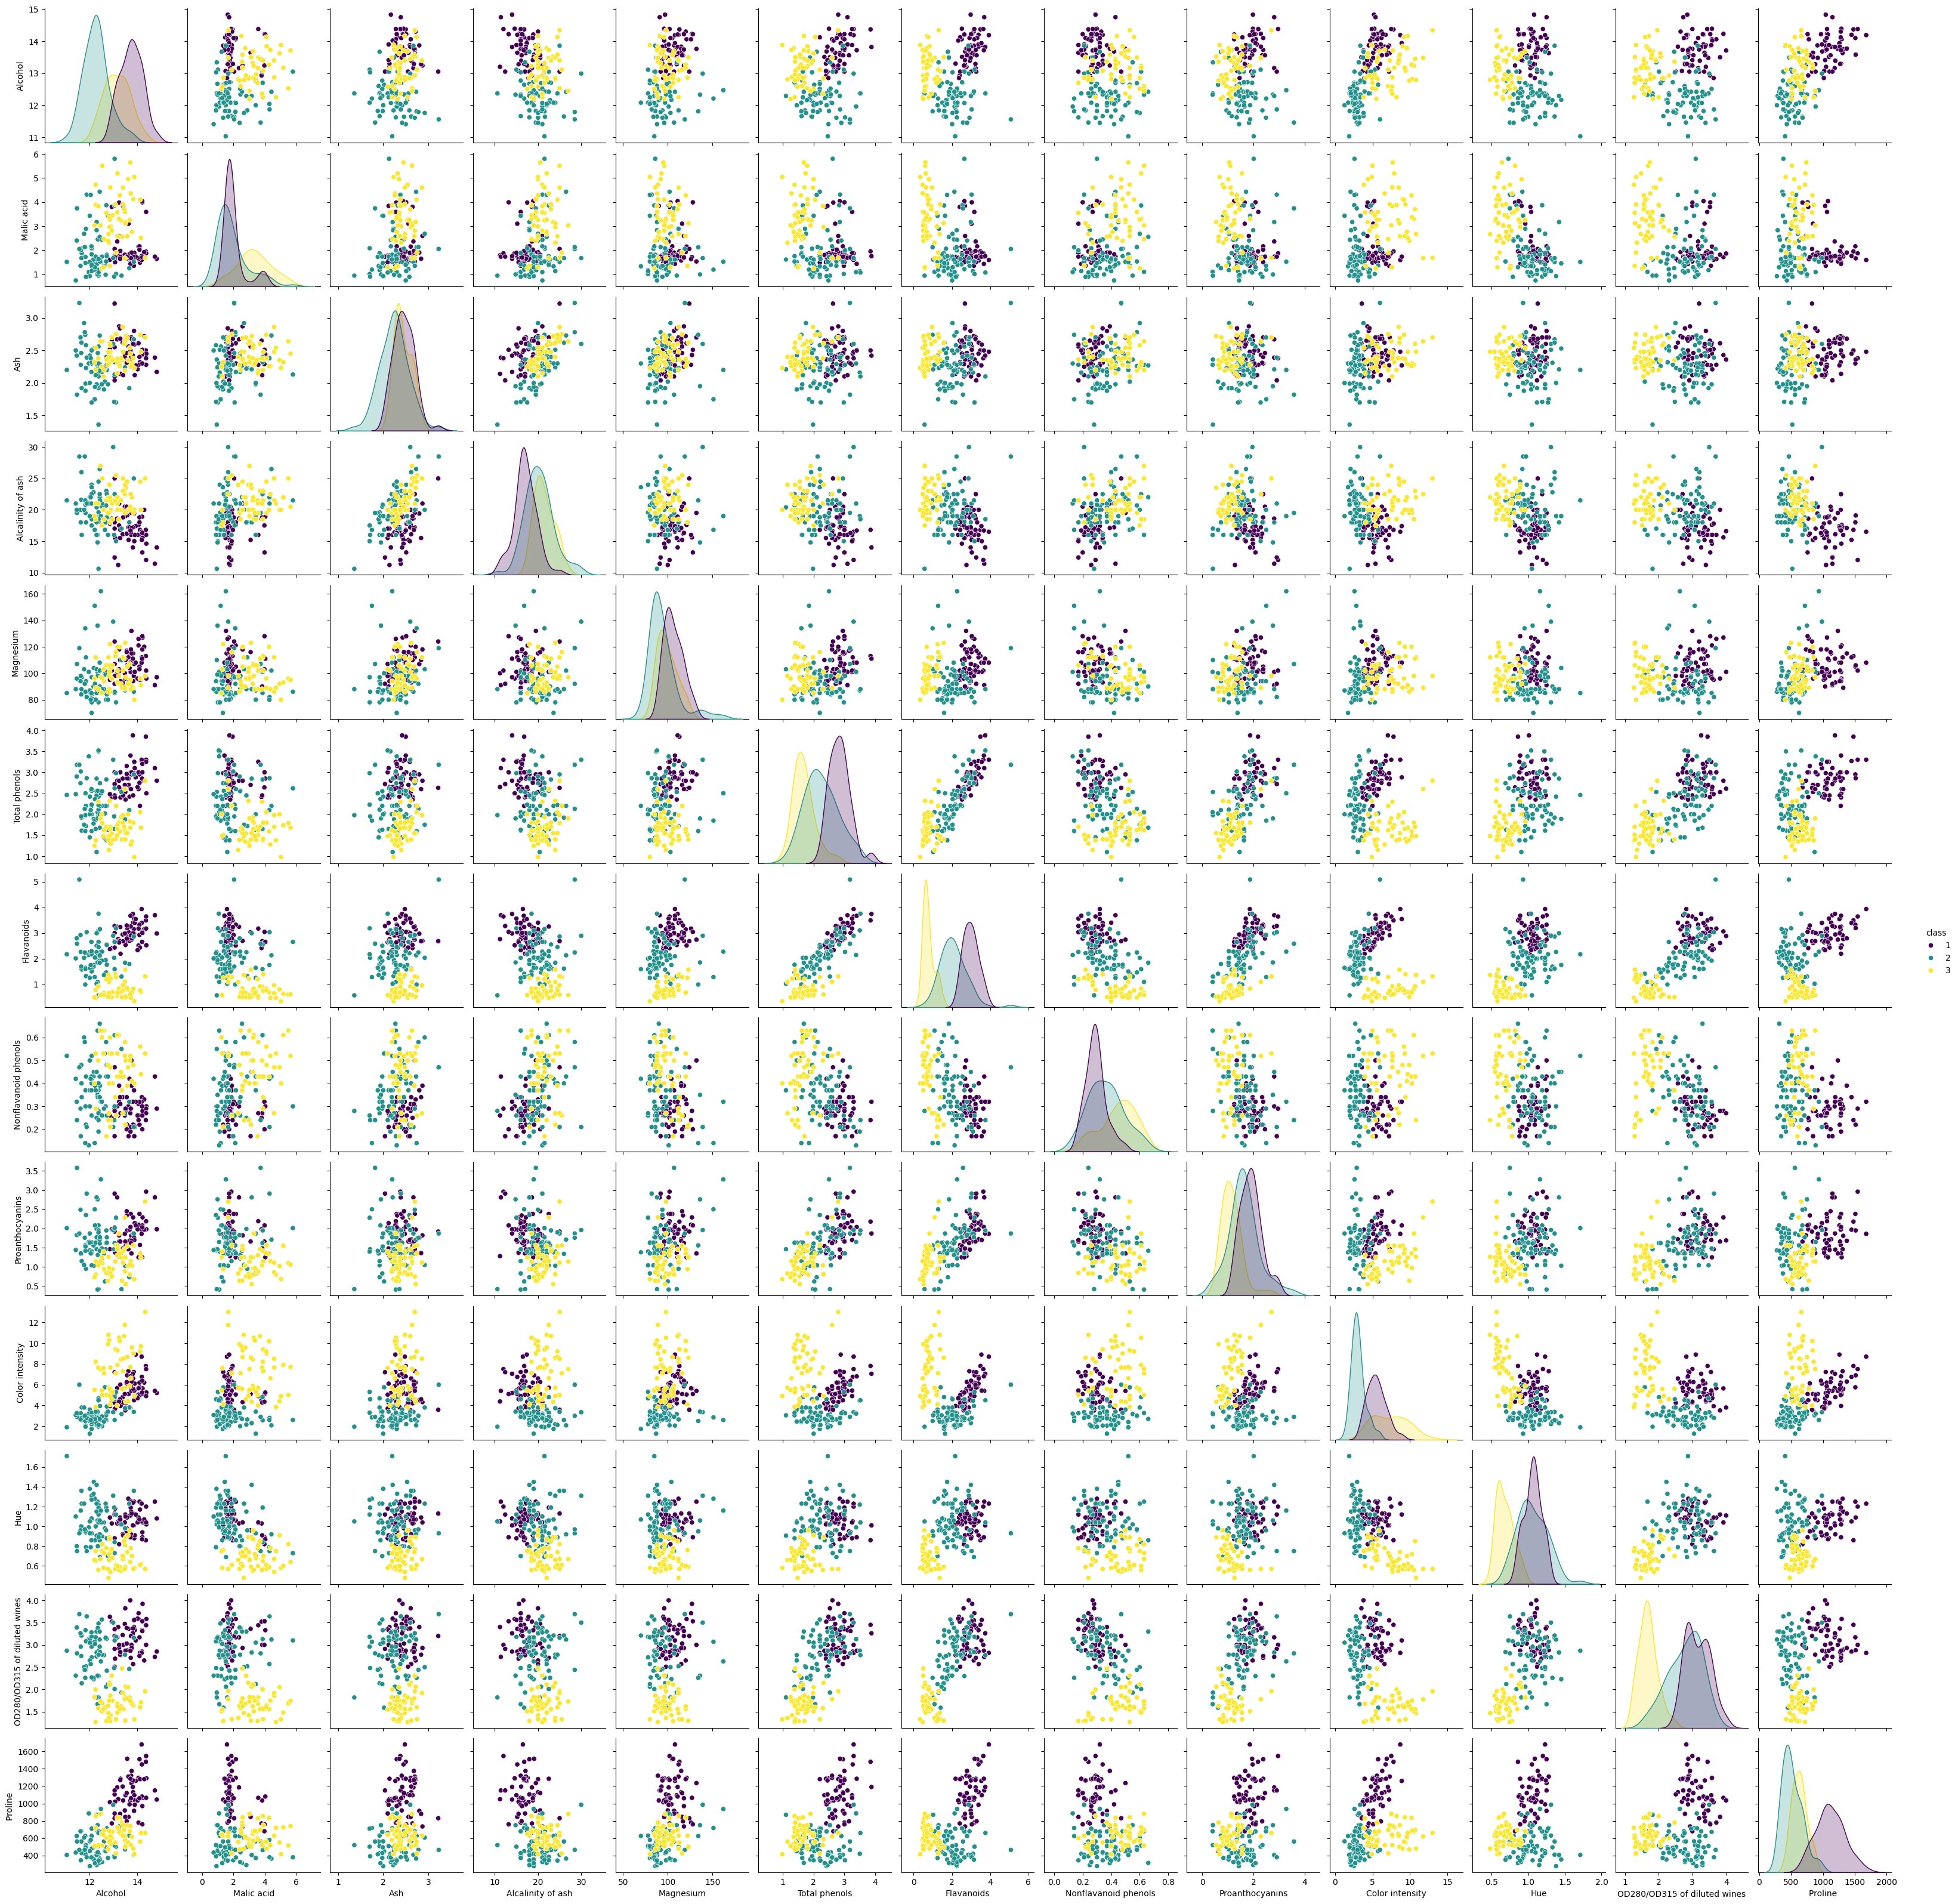

In [8]:
# Pair plot to visualize relationships among features
sns.pairplot(data, hue='class', palette='viridis')
plt.show()

/tmp/ipykernel_575/2565298420.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=data, palette='viridis')


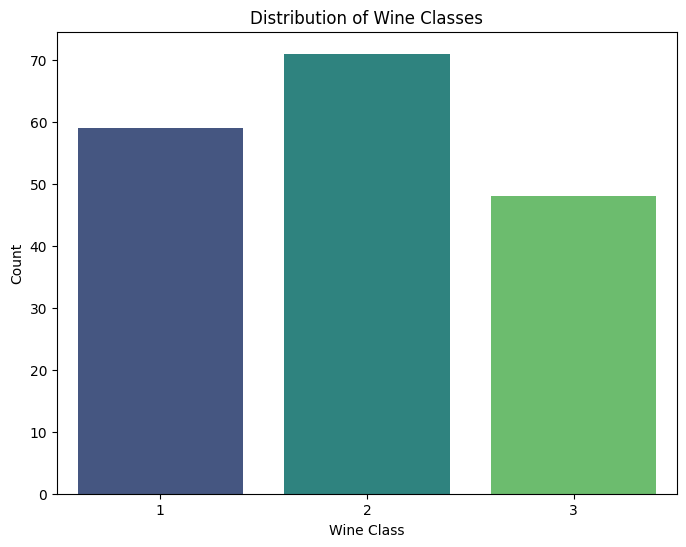

In [9]:
# Visualizing the count of each wine class
plt.figure(figsize=(8, 6))
sns.countplot(x='class', data=data, palette='viridis')
plt.title('Distribution of Wine Classes')
plt.xlabel('Wine Class')
plt.ylabel('Count')
plt.show()

 **3. Normalize features using StandardScaler().**

In [10]:
# Drop the class column in another dataframe
X= data.drop('class', axis= 1)
y = data['class']

In [11]:
# split the data into train test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, test_size= 0.2, stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(142, 13)
(36, 13)
(142,)
(36,)


In [12]:
# Normalize the features of the training dataset using a StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(142, 13)
(36, 13)


**4. Train LogisticRegression**

In [14]:
# Train the Logistic Regression model
lg_Regression_model = LogisticRegression(max_iter=200, random_state=42)
lg_Regression_model.fit(X_train_scaled, y_train)


LogisticRegression(max_iter=200, random_state=42)

In [15]:
# Predict the logistic regression model
y_predict_lg_Regression_model = lg_Regression_model.predict(X_test_scaled)
print(y_predict_lg_Regression_model)

[1 2 1 2 2 1 1 2 2 3 2 3 1 3 1 2 2 1 2 1 2 2 1 1 2 2 1 3 2 3 1 3 2 3 3 3]


In [16]:
# checking the probability of each class by using Logistic Regression model
probabilities = lg_Regression_model.predict_proba(X_test_scaled)
print(probabilities)

[[9.99670802e-01 3.06618686e-04 2.25789222e-05]
 [7.05146567e-03 5.40422989e-01 4.52525546e-01]
 [9.92000329e-01 7.66358777e-03 3.36083043e-04]
 [2.89967381e-01 7.07467362e-01 2.56525772e-03]
 [3.30319998e-02 9.62312788e-01 4.65521250e-03]
 [9.99166474e-01 7.70158779e-04 6.33671384e-05]
 [9.99351799e-01 1.51739451e-04 4.96461316e-04]
 [4.26441697e-02 9.57334994e-01 2.08363753e-05]
 [1.05469807e-02 9.42903728e-01 4.65492911e-02]
 [2.41702841e-03 2.46441894e-04 9.97336530e-01]
 [3.11826260e-02 9.61404027e-01 7.41334663e-03]
 [4.15695970e-02 9.05900390e-02 8.67840364e-01]
 [9.99846971e-01 1.13278178e-04 3.97508796e-05]
 [1.73194429e-02 3.81893357e-01 6.00787200e-01]
 [9.99993578e-01 5.24890936e-06 1.17321669e-06]
 [3.00380454e-04 9.99648699e-01 5.09209551e-05]
 [1.22564575e-03 9.96673764e-01 2.10058988e-03]
 [9.92638989e-01 7.26646380e-03 9.45475416e-05]
 [2.45672269e-03 9.97483231e-01 6.00460605e-05]
 [6.58538732e-01 3.40164247e-01 1.29702130e-03]
 [3.17793806e-03 9.96771591e-01 5.047133

In [17]:
# comparing  the probability and prediction value of each class
print("y_predict_values --> probabilities_values")
for i in range(len(X_test)):
  print(y_predict_lg_Regression_model[i], "-->" , probabilities[i])

y_predict_values --> probabilities_values
1 --> [9.99670802e-01 3.06618686e-04 2.25789222e-05]
2 --> [0.00705147 0.54042299 0.45252555]
1 --> [9.92000329e-01 7.66358777e-03 3.36083043e-04]
2 --> [0.28996738 0.70746736 0.00256526]
2 --> [0.033032   0.96231279 0.00465521]
1 --> [9.99166474e-01 7.70158779e-04 6.33671384e-05]
1 --> [9.99351799e-01 1.51739451e-04 4.96461316e-04]
2 --> [4.26441697e-02 9.57334994e-01 2.08363753e-05]
2 --> [0.01054698 0.94290373 0.04654929]
3 --> [2.41702841e-03 2.46441894e-04 9.97336530e-01]
2 --> [0.03118263 0.96140403 0.00741335]
3 --> [0.0415696  0.09059004 0.86784036]
1 --> [9.99846971e-01 1.13278178e-04 3.97508796e-05]
3 --> [0.01731944 0.38189336 0.6007872 ]
1 --> [9.99993578e-01 5.24890936e-06 1.17321669e-06]
2 --> [3.00380454e-04 9.99648699e-01 5.09209551e-05]
2 --> [0.00122565 0.99667376 0.00210059]
1 --> [9.92638989e-01 7.26646380e-03 9.45475416e-05]
2 --> [2.45672269e-03 9.97483231e-01 6.00460605e-05]
1 --> [0.65853873 0.34016425 0.00129702]
2 --> 

In [18]:
# Evaluating Logistic Regression Model
Accuracy = accuracy_score(y_test, y_predict_lg_Regression_model)
print(f'Prediction Accuracy: {Accuracy:.2f}')

Prediction Accuracy: 0.97


In [19]:
# Evaluate Precision, F1 Score, Recall
Precision = precision_score(y_test, y_predict_lg_Regression_model, average = "macro")
Recall = recall_score(y_test, y_predict_lg_Regression_model, average = "macro")
F1_Score = f1_score(y_test, y_predict_lg_Regression_model, average = "macro")
print("Precision = ", Precision, "Recall = ", Recall, "F1_Score = ", F1_Score)

Precision =  0.9777777777777779 Recall =  0.9666666666666667 F1_Score =  0.9709618874773139


**5. Plot the confusion matrix heatmap and plot the decision boundary visualization.**

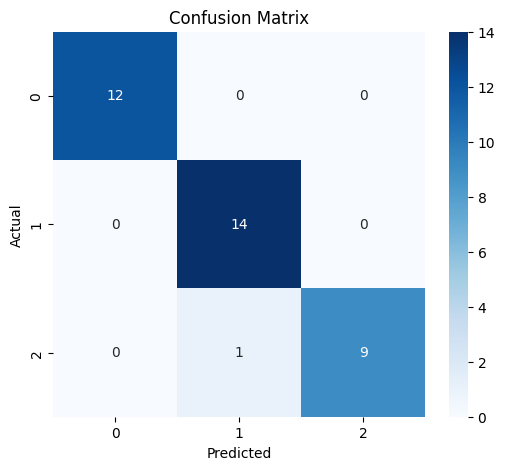

In [20]:
# Plotting the confusion matrix
cm = confusion_matrix(y_test, y_predict_lg_Regression_model,)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Remaining Information: 0.551


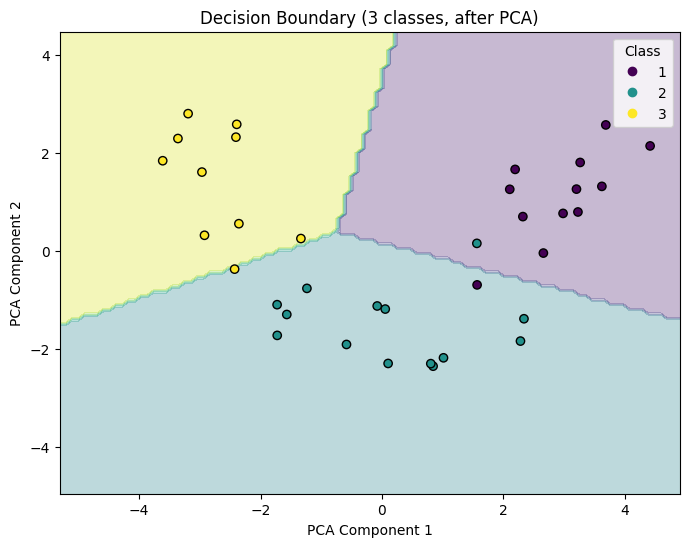

In [21]:
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)

print("Remaining Information:", pca.explained_variance_ratio_.sum().round(3))

# Use these decomposited features for ploting
model_2d = LogisticRegression(max_iter=500, random_state=42)
model_2d.fit(X_train_2d, y_train)

#  Decision boundary plot
fig, ax = plt.subplots(figsize=(8, 6))
DecisionBoundaryDisplay.from_estimator(
    model_2d, X_train_2d,
    response_method="predict",
    alpha=0.3, ax=ax
)
scatter = ax.scatter(
    X_test_2d[:, 0], X_test_2d[:, 1],
    c=np.asarray(y_test), edgecolor="k"
)
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_title("Decision Boundary (3 classes, after PCA)")
ax.legend(*scatter.legend_elements(), title="Class")
plt.show()

**4. Train DecisionTreeClassifier**

In [22]:
DT_model = DecisionTreeClassifier()
DT_model.fit(X_train, y_train)
y_predict_DT_model = DT_model.predict(X_test)
print(y_predict_DT_model)

[1 3 1 2 2 1 1 2 2 3 2 3 1 3 1 2 2 1 2 2 2 2 1 1 2 2 1 3 2 3 1 3 2 3 3 3]


In [23]:
DT_model_Accuracy = accuracy_score(y_test,y_predict_DT_model)
DT_model_precision = precision_score(y_test, y_predict_DT_model, average = "macro")
DT_model_recall = recall_score(y_test, y_predict_DT_model, average = "macro")
DT_model_f1_score = f1_score(y_test, y_predict_DT_model, average = "macro")


In [24]:
print("Decision Tree Classifier Accuracy = ", DT_model_Accuracy)
print("Precision = ", DT_model_precision)
print("Recall = ", DT_model_recall)
print("F1 Score = ", DT_model_f1_score)

Decision Tree Classifier Accuracy =  0.9722222222222222
Precision =  0.9777777777777779
Recall =  0.9722222222222222
F1 Score =  0.9740129935032483


**5. Plot the confusion matrix heatmap and plot the decision boundary visualization.**

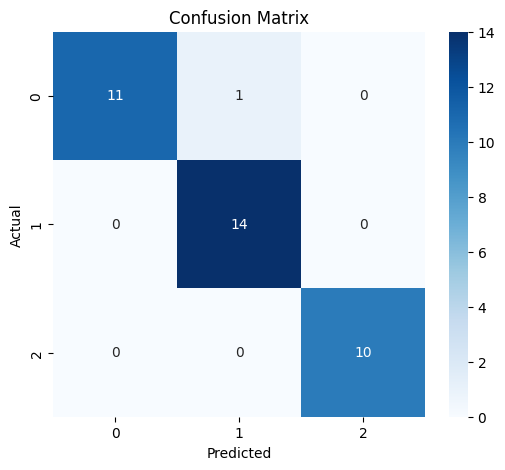

In [25]:
# Plotting the confusion matrix
cm = confusion_matrix(y_test, y_predict_DT_model,)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Remaining Information: 0.551


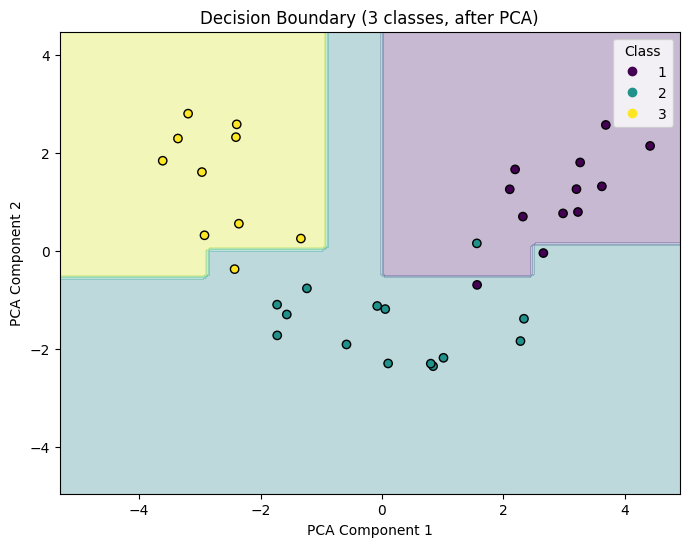

In [26]:
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)

print("Remaining Information:", pca.explained_variance_ratio_.sum().round(3))

# Use these decomposited features for ploting
DT_model_2d = DecisionTreeClassifier()
DT_model_2d.fit(X_train_2d, y_train)

#  Decision boundary plot
fig, ax = plt.subplots(figsize=(8, 6))
DecisionBoundaryDisplay.from_estimator(
    DT_model_2d, X_train_2d,
    response_method="predict",
    alpha=0.3, ax=ax
)
scatter = ax.scatter(
    X_test_2d[:, 0], X_test_2d[:, 1],
    c=np.asarray(y_test), edgecolor="k"
)
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_title("Decision Boundary (3 classes, after PCA)")
ax.legend(*scatter.legend_elements(), title="Class")
plt.show()

**Benchmark classification accuracy, precision, recall, and F1-score.**

In [27]:
Final_result = pd.DataFrame(
    {
        "LogisticRegression" : [Accuracy, Precision,  Recall, F1_Score],
        "DecisionTreeClassifier" : [DT_model_Accuracy, DT_model_precision, DT_model_recall, DT_model_f1_score]

    },
    index=["Accuracy", "Precision", "Recall", "F1-Score"]
).T

styled = (
    Final_result.round(3)
    .style
    .background_gradient(cmap="Blues", axis= None, vmin=0.5, vmax=1.0)
    .highlight_max(axis=0, props="font-weight: bold; border: 2px solid green;")
    .format("{:.3f}")
    .set_caption("Model Benchmark: Logistic Regression vs Decision Tree")
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "16px"), ("font-weight", "bold")]},
        {"selector": "th", "props": [("text-align", "center")]},
    ])
)
styled

,Accuracy,Precision,Recall,F1-Score
LogisticRegression,0.972,0.978,0.967,0.971
DecisionTreeClassifier,0.972,0.978,0.972,0.974
